In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

conn = sqlite3.connect("../data/powerlifting.db")

q_edad = """
SELECT CAST(Age AS INTEGER) AS edad, Sex,
       COUNT(*) AS registros,
       ROUND(AVG(Dots), 1) AS dots_promedio
FROM powerlifting
WHERE Equipment = 'Raw' AND Sex IN ('M', 'F')
  AND Age = CAST(Age AS INTEGER) AND Age BETWEEN 14 AND 70
GROUP BY edad, Sex
HAVING COUNT(*) >= 200
ORDER BY Sex, edad
"""

q_mejor = """
WITH ranking AS (
    SELECT Name, Sex, Age, Dots,
           ROW_NUMBER() OVER (PARTITION BY Name, Sex ORDER BY Dots DESC) AS puesto,
           COUNT(*) OVER (PARTITION BY Name, Sex) AS total_comps
    FROM powerlifting
    WHERE Equipment = 'Raw' AND Sex IN ('M', 'F')
      AND Age = CAST(Age AS INTEGER)
)
SELECT Sex, CAST(Age AS INTEGER) AS edad_mejor_marca, COUNT(*) AS levantadores
FROM ranking
WHERE puesto = 1 AND total_comps >= 5
GROUP BY Sex, edad_mejor_marca
ORDER BY Sex, edad_mejor_marca
"""

edad = pd.read_sql_query(q_edad, conn)
mejor = pd.read_sql_query(q_mejor, conn)

# Porcentaje de levantadores por edad de mejor marca, dentro de cada sexo
mejor["pct"] = mejor["levantadores"] / mejor.groupby("Sex")["levantadores"].transform("sum") * 100

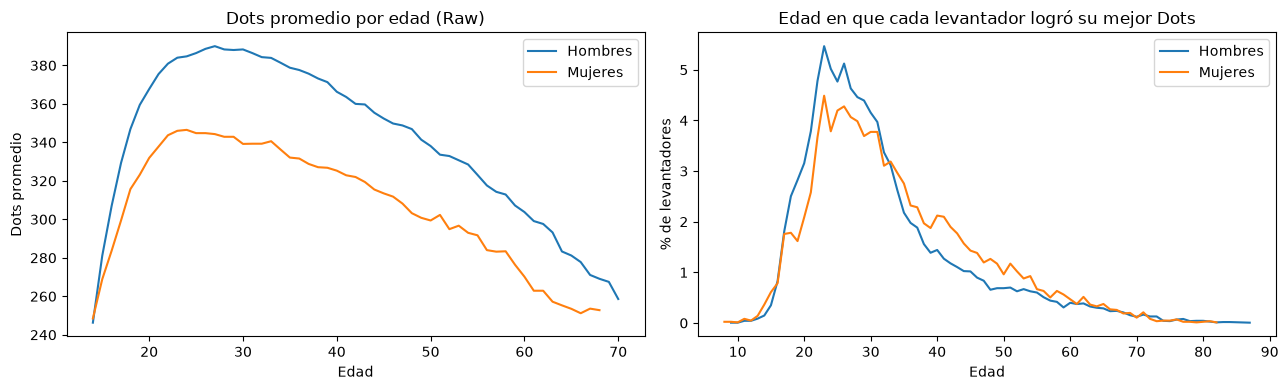

In [2]:
etiquetas = {"M": "Hombres", "F": "Mujeres"}
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

for sexo in ["M", "F"]:
    d = edad[edad["Sex"] == sexo]
    ax[0].plot(d["edad"], d["dots_promedio"], label=etiquetas[sexo])
    m = mejor[mejor["Sex"] == sexo]
    ax[1].plot(m["edad_mejor_marca"], m["pct"], label=etiquetas[sexo])

ax[0].set_title("Dots promedio por edad (Raw)")
ax[0].set_xlabel("Edad"); ax[0].set_ylabel("Dots promedio"); ax[0].legend()

ax[1].set_title("Edad en que cada levantador logró su mejor Dots")
ax[1].set_xlabel("Edad"); ax[1].set_ylabel("% de levantadores"); ax[1].legend()

plt.tight_layout()
plt.savefig("../images/edad.png", dpi=150)
plt.show()